# 06 Â· Camera verification desk

**Mission.** Track evidence and privacy constraints for public camera observations.

![Illustrated OSIRIS VEOC mission board](assets/veoc-splash.svg)

> **Exercise only.** All sectors, calls, flood depths, beds, and travel times below are invented. Run each notebook independently with the **Python (Pyodide)** kernel in JupyterLite. First startup downloads the browser runtime. The linked OSIRIS console is a separate application.

[Book home](intro.md) Â· [2D operations map](https://jltobias.github.io/JupyterLite-Osiris/scenes/operations-2d.html) Â· [3D scene](https://jltobias.github.io/JupyterLite-Osiris/scenes/operations-3d.html) Â· [OSIRIS](https://osirisai.live/)

In [1]:
import math, json, statistics
from datetime import datetime, timezone
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML, Markdown
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False})
SECTORS = [
 {"name":"Harbor", "lat":29.93,"lon":-90.07,"population":18000,"calls":34,"flood_m":0.9,"open_beds":12,"road_min":28,"reporting":0.84},
 {"name":"Eastbank","lat":29.96,"lon":-90.00,"population":24000,"calls":22,"flood_m":0.4,"open_beds":24,"road_min":19,"reporting":0.91},
 {"name":"Canal",   "lat":29.98,"lon":-90.10,"population":12000,"calls":31,"flood_m":1.4,"open_beds":4, "road_min":42,"reporting":0.68},
 {"name":"North",   "lat":30.05,"lon":-90.07,"population":30000,"calls":18,"flood_m":0.1,"open_beds":38,"road_min":14,"reporting":0.96},
 {"name":"Bayou",   "lat":29.89,"lon":-90.12,"population":9000, "calls":25,"flood_m":1.1,"open_beds":7, "road_min":51,"reporting":0.72},
 {"name":"Airport", "lat":30.00,"lon":-90.25,"population":16000,"calls":11,"flood_m":0.2,"open_beds":18,"road_min":23,"reporting":0.89},
]
for sector in SECTORS:
    sector["rate_10k"] = sector["calls"] / sector["population"] * 10000
print("EXERCISE DATA â€” fictional sectors, observations and facilities; no real incident implied")

EXERCISE DATA â€” fictional sectors, observations and facilities; no real incident implied


OSIRIS indexes public camera feeds and snapshots from many operators. Availability differs by operator. A camera can corroborate visible conditions in its field of view; it cannot prove conditions off camera or after its last frame. Respect the operator terms and avoid collecting identifiable people or license plates.

In [2]:
claims=[("Canal underpass flooded","Public camera frame",2,0.65),("Bayou road blocked","Field report",1,0.88),("Harbor bridge open","No current view",5,0.25)]
for claim,source,age,quality in claims:
    freshness=math.exp(-age/3)
    score=quality*freshness
    print(f"{claim:25} {source:20} age={age}h  illustrative evidence score={score:.2f}")

Canal underpass flooded   Public camera frame  age=2h  illustrative evidence score=0.33
Bayou road blocked        Field report         age=1h  illustrative evidence score=0.63
Harbor bridge open        No current view      age=5h  illustrative evidence score=0.05


The score is a **teaching heuristic**, not an OSIRIS confidence score. Recording the source, frame timestamp, viewpoint, and verification owner matters more than collapsing evidence to a number.

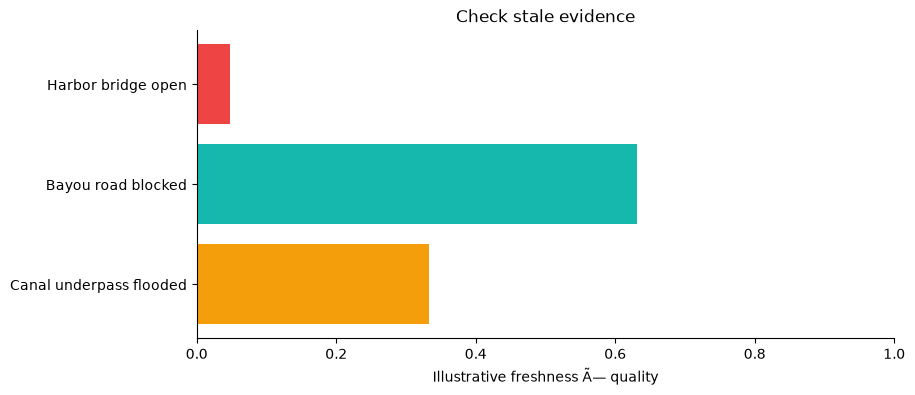

In [3]:
fig,ax=plt.subplots();ax.barh([c[0] for c in claims],[c[3]*math.exp(-c[2]/3) for c in claims],color=['#f59e0b','#16b8ad','#ef4444']);ax.set(xlim=(0,1),xlabel='Illustrative freshness Ã— quality',title='Check stale evidence');plt.show()

## Field exercise and review
Draft a verification log row for a camera snapshot: operator, camera URL, frame time, retrieval time, visible finding, blind spots, reviewer, and next check.

## Source desk
- [OSIRIS source and MIT license](https://github.com/simplifaisoul/osiris) Â· [OSIRIS live console](https://osirisai.live/)
- [USGS Earthquake API](https://earthquake.usgs.gov/fdsnws/event/1/) Â· [NASA EONET](https://eonet.gsfc.nasa.gov/docs/v3) Â· [NASA FIRMS](https://firms.modaps.eosdis.nasa.gov/)
- [NOAA National Hurricane Center](https://www.nhc.noaa.gov/) Â· [GDACS](https://www.gdacs.org/) Â· [OpenSky Network](https://opensky-network.org/)

**Use rule:** A source link provides context, not independent confirmation of this fictional exercise. Check timestamps, geography, provider terms, and incident command procedures before any real decision.